![Banner](../../../../Images/Banner/07_remote_sensing/09_09_banner_rs_image_classification.png)


# Introduction to Image Classification

A satellite image is a grid of numbers.

Fifteen notebooks turn that grid into a map of categories, from a single Landsat scene to multi-sensor fusion. Self-supervised pretraining and geospatial foundation models have their own chapter, `09_11_foundations_models`.

- **Introduction to Image Classification.** This notebook. What is labelled (a pixel, a segment, a chip, or a box), how many labels exist, and which model reads the image.
- **Image Processing.** Clean, resample, stretch, filter, and add edge and texture layers before a classifier sees the image.
- **Sampling, Accuracy Assessment and Reproducible Runs.** How the split changes the reported accuracy, with uncertainty, area-adjusted estimates, and a reproducible run.
- **Classical Image Classification: Pixel-Based and Object-Based.** Land cover and crop type in the Corn Belt from one mid-season Landsat scene and the 2025 Cropland Data Layer.
- **Image Classification with a CNN on the GPU: Landsat and the Cropland Data Layer.** A neighbourhood CNN on the same 2025 Landsat scene.
- **Deep Learning for Sentinel-2: CNN, ResNet, EfficientNet, ConvNeXt, ViT and Swin on the GPU.** Those architectures on a late-August 2025 Sentinel-2 scene of the Corn Belt.
- **Transfer Learning and Vision Transformers for Sentinel-2: ImageNet vs Remote-Sensing Weights.** A linear probe, partial fine-tuning, and full fine-tuning from ImageNet and remote-sensing weights.
- **Crop Classification with Sentinel-1 SAR Time Series: Pixel Classifiers and Deep CNNs (VV/VH, May-October 2024).** VV and VH backscatter through a growing season, with pixel classifiers and CNNs.
- **Spatio-Temporal and Multi-Sensor Crop Mapping: Sentinel-2, Sentinel-1 and Landsat Time Series, 2020 to 2025.** Six seasons of three sensors, using when a crop greens up and senesces.
- **Mapping Wetland Paddy in Bangladesh with a 2025 to 2026 Sentinel-1 Time Series.** Cloud-free SAR for flooded rice and the dates of its management.
- **Change Detection: Classical, Post-Classification and Deep Methods on Landsat and Sentinel-2, 2020 to 2025.** What differs between two dates, including the corn-soybean rotation.
- **Semantic Segmentation of Crop Types from Sentinel-2: FCN, U-Net, DeepLabV3(+) and SegFormer on the GPU.** A class for every pixel, so field edges are kept.
- **Instance Segmentation of Agricultural Fields with Mask R-CNN.** A separate mask for each field on eight-band WorldView-2.
- **Imperfect labels and domain shift.** Few labels, noisy maps, and a model applied to another year or place.
- **Multi-sensor image fusion.** MODIS, Landsat, Sentinel-2, Sentinel-1, and finer commercial or aerial images in one map.


## Overview

Image classification turns those numbers into a map of **categories**: water, building, corn, soybean, burned, changed. The word covers a wide family of problems that differ in *what is labeled* (a pixel, a segment, a whole chip, a box), *how much labeled data exists* (none, a few points, a lot), and *what model reads the image* (a clustering rule, a random forest, a convolutional network, a foundation model). This notebook is the map of that family. It defines each type, says when it fits, and shows what `geolattice.rsense.classify.image_classification` offers for it, with a small hands-on example on Sentinel-2 data.

Section 12 is a guide to the notebooks of this chapter (09_09). Finding individual **objects** (trees, swimming pools, field boundaries) has its own chapter, `09_10_object_detection`, which starts with `09_10_00_object_detection.ipynb`. Here object detection is only placed in the family of tasks (Sections 2 and 6.2).


## Core concepts

### Learning objectives

1. Separate scene classification, pixel classification (semantic segmentation), object detection, instance segmentation, change detection and time-series classification by their input and output.
2. Compare pixel-based and object-based classification.
3. Compare unsupervised, supervised, semi-supervised and self-supervised learning, and name the cases in between (weak labels, active learning, zero-shot).
4. Explain how computer vision differs on satellite imagery, and why leakage-safe validation matters more than model choice.
5. Map every method in this chapter to the GeoLattice function that implements it, and to the notebook that uses it.
6. Run an unsupervised, a supervised, an object-based and a semi-supervised classification on one Sentinel-2 scene and judge them on a spatially separated test set.

### Contents

1. What image classification is
2. Task types
3. The spatial unit: pixel or object
4. Learning paradigms
5. Computer vision on satellite imagery
6. Semantic segmentation and object detection in more detail
7. Available methods
8. Evaluating a classification
9. What GeoLattice offers
10. Hands-on: land cover from a Sentinel-2 scene
11. Choosing a method
12. The notebooks in this chapter
13. Summary, exercises and references


## Image Classification

A multispectral pixel is a vector $\mathbf{x}=(x_1,\dots,x_B)$ of $B$ band values. A classifier is a function $f$ that assigns it one of $K$ classes,

$$\hat{y} = f(\mathbf{x}) \in \{1,\dots,K\}.$$

The classes only make sense next to a **classification scheme**: a fixed, exhaustive and mutually exclusive list such as *pavement, building, tree, grass, water*. Two things make this harder than it looks.

- **Spectral confusion.** Different surfaces look alike (dark roofs and asphalt) and one surface looks different (a tree in sun and in shade). The spectrum alone is rarely enough, so context (texture, shape, neighbours, dates) is added.
- **Mixed pixels.** A 10 m pixel can hold a roof edge, a road and a tree crown. The label describes the dominant cover, not the truth inside the pixel.

The output is a **thematic map**: a raster where each cell holds a class code, with the same CRS and grid as the input. A map without an accuracy statement is only a picture, which is why Section 8 and the GeoLattice evaluation tools matter as much as the classifier.


## The spatial unit: pixel or object

The **spatial unit** is the thing that gets a label. It is a choice independent of the learning paradigm (`ic.SPATIAL_UNITS = ("pixel", "object")`).

| | Pixel-based | Object-based (OBIA) |
|---|---|---|
| Unit | one pixel | a segment of similar neighbouring pixels |
| Features | band values, indices, optionally a window of neighbours | per-segment mean, standard deviation, shape, texture |
| Strengths | simple, fast, no segmentation to tune, works at any resolution | removes "salt-and-pepper" noise, gives polygons, uses shape and texture, fewer units to classify |
| Weaknesses | noisy maps, ignores context unless features add it | the result depends on segmentation scale; under- and over-segmentation both cost accuracy |
| Best for | medium resolution (Landsat, Sentinel-2), spectrally distinct classes | very high resolution (sub-metre), SAR speckle, parcel-like targets |
| GeoLattice | `train_pixel_classifier` + `predict_map` | `object_based_classify` (SLIC by default, `classify/obia.py`) |

Deep networks blur this line. A CNN or U-Net reads a *window* around each pixel, so it learns context itself and is pixel-based in output but object-aware in what it sees.


## Learning paradigms

The paradigm is set by how much labeled data exists (`ic.LEARNING_MODES`).


### Unsupervised

No labels. The algorithm groups pixels by spectral similarity (k-means, mini-batch k-means, Gaussian mixture, ISODATA-style clustering). The result is **clusters**, not classes: an analyst must name them afterwards, and one cluster can mix two classes. Use it to explore an area, to check that classes are separable, or to build a first guess before collecting samples.
GeoLattice: `unsupervised_classify(image, n_classes, method="kmeans" | "minibatch_kmeans" | "gmm")`.


### Supervised
Labeled examples (points, polygons or masks) train a model that predicts the label of unseen pixels. This is the workhorse of operational mapping.

- *Classical machine learning* on hand-built features: random forest, support vector machine, gradient boosting (XGBoost), k-nearest neighbours, logistic regression, small multilayer perceptron. Fast, needs hundreds to thousands of labels, and is easy to interpret.
- *Deep learning* learns the features: CNNs, U-Nets, vision transformers. It needs more labels or a pretrained backbone, and pays off with high resolution, texture and many dates.

GeoLattice: `train_pixel_classifier(model="rf" | "svm" | "xgb" | "knn" | "logistic" | "gbm" | "mlp")`, `train_model` for networks.


### Semi-supervised
A few labels plus a large pool of unlabeled pixels. The model labels the pool itself (**pseudo-labels**) and learns from the confident ones, or it is trained so that its predictions stay consistent under perturbation. Gains are real when labels are scarce and clusters in feature space respect the classes, and they can be zero or negative when the first model is badly wrong, because it then teaches itself its own mistakes.
GeoLattice: `self_training`, `pseudo_label`, `fixmatch_loss`, `train_fixmatch`.


### Self-supervised
No labels *for pretraining*. The model solves a task made from the images themselves: pulling two views of the same place together and pushing others apart (contrastive learning: SimCLR, MoCo, SeCo), or reconstructing masked patches (masked autoencoders). The learned **encoder** is then reused with a few labels through a linear probe or fine-tuning. Satellite archives are huge and mostly unlabeled, so this is the main route to *geospatial foundation models*.
GeoLattice: `pretrain_contrastive`, `build_mae`, `pretrain_masked`, `extract_embeddings`, `linear_probe`.


### Related settings
| Setting | Idea | GeoLattice |
|---|---|---|
| Transfer learning | start from ImageNet or remote-sensing weights | `build_cnn(pretrained=True)`, `load_rs_backbone`, `set_trainable`, `compare_transfer_modes` |
| Weak supervision | train on an existing coarse product (for example a land-cover map) | `weak_labels_from_product` |
| Active learning | the model asks for the most informative samples | `uncertainty_scores`, `select_for_labeling`, `active_learning_loop` |
| Noise-robust training | labels contain errors | `get_loss("gce" \| "sce")` |
| Domain adaptation | train on one region or sensor, apply to another | `coral`, `histogram_match`, `tent_adapt` |
| Zero- and few-shot | no or very few examples per class | `zero_shot_classify`, `few_shot_prototypes`, `embedding_search` |


## Computer vision on satellite imagery

Computer vision supplies most of the models, and the reasons they do not transfer unchanged are the reasons for GeoLattice's design.

| Natural photos | Satellite and aerial imagery | Consequence |
|---|---|---|
| 3 bands (RGB) | 4 to hundreds of bands, plus SAR, DEM, indices | replace the first convolution: `adapt_input_channels`, `build_cnn(in_channels=...)` |
| Objects upright, large, centred | seen from above, any orientation, tiny, dense | rotation and flip augmentation: `OverheadAugment`; oriented boxes: `obb_to_polygon` |
| Images are independent | neighbouring pixels are correlated (spatial autocorrelation) | split by geography: `spatial_block_split` |
| Fixed image size | scenes are gigapixels and georeferenced | tile, predict, blend seams, write back with CRS: `sliding_window_predict`, `write_class_map` |
| Camera pixels are comparable | digital numbers, reflectance and backscatter differ by sensor and date | normalize with statistics from training data only: `Normalizer` |
| Each photo is one time | repeat acquisitions carry phenology | temporal models: `build_temporal_model` |

The main architecture families:

- **Convolutional networks** (LeNet, VGG, ResNet, EfficientNet, ConvNeXt) learn local patterns. Their reach is the **receptive field**, the ground area one output sees. `receptive_field(model)` reports it, which tells you whether a network can even see a building or a field.
- **Encoder-decoder segmenters** (FCN, U-Net, DeepLabV3+, FPN, PSPNet, SegFormer) turn that into a per-pixel map.
- **Vision transformers** (ViT, Swin) use attention across patches, see global context, and scale well with unlabeled pretraining. `vit_attention_rollout` shows where they look.
- **Foundation models** (Prithvi-EO, Clay, SatlasPretrain, DOFA, SSL4EO, SatMAE, Scale-MAE, SkySense) are large encoders pretrained on global archives. `foundation_model_info` lists them and `load_foundation_encoder` loads them.


## Semantic segmentation and object detection in more detail


### Semantic segmentation
A network maps an image tile of shape $(B,H,W)$ to class scores of shape $(K,H,W)$, and the arg-max is the class map. U-Net style encoder-decoders downsample to gather context and upsample to recover detail, with skip connections that carry sharp edges across. Training uses a per-pixel loss (cross-entropy, Dice, focal, Lovasz) and, for thin classes such as field boundaries, `boundary_weight_map`. Large scenes are predicted tile by tile with overlap, and `sliding_window_predict` blends the seams.
Metrics are per-class **IoU** (intersection over union), Dice/F1, precision, recall and mean IoU: `segmentation_metrics`.


### 6.2 Object detection
A detector returns a list of boxes with a class and a score, not a class map.

- *Two-stage* detectors (Faster R-CNN, Mask R-CNN) propose regions, then classify them: accurate, slower.
- *One-stage* detectors (RetinaNet, FCOS, YOLO) predict boxes directly: faster.
- *Oriented boxes* (YOLO-OBB) fit objects seen from above at any angle, such as ships, planes and buildings.

Satellite scenes are far larger than a detector's input, so they are cut into overlapping tiles (`detection_tiles`), run (`detect_objects`), and the duplicates at tile edges are merged with non-maximum suppression (`nms`, `merge_detections`). Quality is **mean average precision** at an IoU threshold: `mean_average_precision`. `count_objects` summarizes detections per zone.

Agricultural fields are a special case: they touch and fill the landscape, so they are found through the **boundaries** between them rather than with boxes (`geolattice.rsense.edge_detectors`).

The `09_10_object_detection` chapter covers all of this in detail:
- `09_10_00` introduces IoU, NMS, mAP, the detector families and boundary networks;
- `09_10_01` detects swimming pools and trees;
- `09_10_02` to `09_10_04` delineate fields in Google screenshots, WorldView and Sentinel-2 imagery.


## Available methods

A compact catalog, from classical to modern. Cost is relative, for a typical regional map.

| Family | Methods | Labels needed | Compute | Strength | Limit |
|---|---|---|---|---|---|
| Rule-based | thresholds on indices (NDVI, NDWI, SAR ratios) | none | trivial | transparent | brittle across scenes |
| Clustering | k-means, GMM | none | low | exploration | clusters are not classes |
| Classical ML | random forest, SVM, XGBoost, kNN, MLP | hundreds to thousands | low | strong baseline, interpretable | no spatial context unless engineered |
| Object-based | segmentation + classifier | hundreds of objects | low to medium | clean polygons | scale sensitive |
| CNN / ViT chips | ResNet, EfficientNet, ConvNeXt, ViT, Swin | thousands | medium to high | learns features | needs chips and GPU |
| Segmentation nets | U-Net, DeepLabV3+, SegFormer | masks | high | wall-to-wall maps | needs masks |
| Detectors | Faster R-CNN, RetinaNet, YOLO | boxes | high | counts, locations | needs boxes |
| Temporal | TempCNN, LSTM, L-TAE, PSE-TAE, U-TAE | labels on a time series | medium to high | crop phenology | needs a regular stack |
| Multi-sensor fusion | early, middle, late optical + SAR | as above | medium | cloud-robust | co-registration |
| Self-supervised | SimCLR/MoCo, masked autoencoder | none, then few | very high pretrain | label-efficient | pretraining cost |
| Foundation models | Prithvi, Clay, Satlas, DOFA, SSL4EO | few | inference or fine-tune | strong transfer | check license and input spec |
| Promptable / vision-language | SAM, RemoteCLIP, GeoRSCLIP | none | medium | quick, zero-shot | unverified output |

Two rules of thumb. Start with a random forest on good features: it is the baseline every deep model has to beat, and `compare_with_baselines` makes the comparison explicit. Move to deep learning when the image *itself* (texture, shape, context, dates) carries the signal and there are enough labels or a good pretrained encoder.


## Evaluating a classification

Most reported accuracy in remote sensing is too high, and the cause is almost always **spatial leakage**. Neighbouring pixels are near-duplicates, so a random split puts almost the same pixel in train and test and rewards memorization. A fair test holds out whole **blocks** of ground. The same holds in time (hold out later dates) and across places (hold out a region).

| Do | GeoLattice |
|---|---|
| Split by spatial block, group (parcel) or date | `spatial_block_split`, `group_split`, `temporal_split`, `spatial_kfold` |
| Confirm nothing is shared between splits | `check_split_isolation`, `check_geographic_overlap` |
| Fit scalers on training data only | `Normalizer` |
| Cross-validate in space | `spatial_cross_validate`, `train_pixel_classifier(coords=..., block_size=...)` |
| Report per-class precision, recall, F1, kappa with intervals | `classification_report(n_boot=...)` |
| Find where the map is wrong | `error_map` |
| Estimate *area* of each class with uncertainty | `geolattice.rsense.classify.accuracy` (Olofsson et al. 2014) |
| Record the run | `save_run`, `load_run` |

Overall accuracy hides rare classes. Read macro-F1 and the per-class table, and when the goal is an **area estimate**, use the area-adjusted estimator, because a map's pixel counts are biased by its own errors.


## What GeoLattice offers

All of it sits in one module that follows the order of a project:

```python
import geolattice.rsense.classify.image_classification as ic     # also: geolattice.rsense.image_classification
```

| # | Section | Main functions |
|---|---|---|
| 1 | Data and task definition | `load_stack`, `RasterMeta`, `labels_from_table`, `rasterize_labels`, `sample_pixels`, `spatial_block_split`, `group_split`, `temporal_split`, `spatial_kfold`, `Normalizer` |
| 2 | Learning paradigm and spatial unit | `unsupervised_classify`, `train_pixel_classifier`, `spatial_cross_validate`, `predict_map`, `object_based_classify` |
| 3 | PyTorch foundations | `ChipDataset`, `extract_chips`, `chips_from_folder`, `build_cnn`, `receptive_field`, `OverheadAugment`, `cutmix`, `get_loss`, `train_model` |
| 4 | Transfer learning and transformers | `set_trainable`, `load_rs_backbone`, `compare_transfer_modes`, `vit_attention_rollout` |
| 5 | Semantic segmentation | `build_segmenter`, `sliding_window_predict`, `write_class_map`, `segmentation_metrics` |
| 6 | Object detection | `build_object_detector`, `box_iou`, `nms`, `mean_average_precision`, `detection_tiles`, `merge_detections`, `count_objects` |
| 7 | Instance segmentation and boundaries | `clean_mask`, `instances_from_semantic`, `boundary_weight_map`, `polygonize`, `instances_from_detector`, `export_vectors` |
| 8 | Change detection | `image_ratio`, `image_difference`, `change_vector_analysis`, `pca_change`, `check_coregistration`, `build_change_model`, `change_metrics` |
| 9 | Spatio-temporal and multi-sensor | `pixel_time_series`, `build_temporal_model`, `build_fusion_model`, `fuse_early`, `fuse_late`, `sar_assisted_gap_fill`, `pansharpen` |
| 10 | Self-supervised pretraining | `pretrain_contrastive`, `build_mae`, `pretrain_masked`, `extract_embeddings`, `linear_probe`, `geographic_holdout` |
| 11 | Geospatial foundation models | `foundation_model_info`, `load_foundation_encoder`, `terratorch_config`, `embedding_search`, `few_shot_prototypes` |
| 12 | Promptable and vision-language models | `sam_segment`, `text_prompt_segment`, `load_rs_clip`, `zero_shot_classify` |
| 13 | Few or imperfect labels | `select_for_labeling`, `active_learning_loop`, `self_training`, `train_fixmatch`, `weak_labels_from_product`, `coral`, `histogram_match`, `tent_adapt` |
| 14 | Evaluation and reproducibility | `classification_report`, `error_map`, `compare_with_baselines`, `save_run`, `load_run` |

Design choices worth knowing:

- **Georeferencing is kept.** `load_stack` returns an `xarray.DataArray` with CRS, transform, nodata, band names, dates and sensor, so every output map lands on the right grid.
- **Heavy dependencies load on demand.** The classical workflow needs `pip install "geolattice[rsense-classify]"`. Deep learning needs `geolattice[rsense-dl]`. Importing the module does not import PyTorch.
- **Leakage guards are built in**, as the splits and checks of Section 8.
- **One command line** exposes the task, learning mode and spatial unit and runs the classical workflows end to end: `python -m geolattice.rsense.classify.image_classification --help`.
- **Model output is labeled as such.** SAM and vision-language results carry `ic.UNVERIFIED_NOTE`: verify them against imagery or reference data.

Neighbouring modules: `classify/estimators.py` (the `Classifier` wrapper that uses GPU back ends when available), `classify/obia.py` (segmentation and segment features), `classify/accuracy.py` (confusion matrix and area-adjusted accuracy), `classify/change.py`.


## . Hands-on: land cover from a Sentinel-2 scene

The scene is a 170 x 210 pixel, 10 m Sentinel-2 subset with ten bands (B2 to B12), and a table of labeled points for five classes: pavement/road, building, tree/bushes, grass, water. The code runs on a laptop in well under a minute.


**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [ ]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn.model_selection import train_test_split

import geolattice.rsense.classify.image_classification as ic
from geolattice.rsense.classify import Classifier

warnings.filterwarnings("ignore")
DATA = Path("../../../../Data/08_remote_sensing/08_09_image_classification/Sentinel_2_UB")
CLASSES = {1: "Pavement/road", 2: "Building", 3: "Tree/bushes", 4: "Grass", 5: "Water"}
COLORS = ["#8c8c8c", "#d62728", "#1b6e2f", "#9bd96b", "#1f77b4"]
CMAP = ListedColormap(COLORS)
HANDLES = [Patch(color=c, label=CLASSES[k]) for k, c in zip(CLASSES, COLORS)]

print("Tasks         :", ic.TASKS)
print("Learning modes:", ic.LEARNING_MODES)
print("Spatial units :", ic.SPATIAL_UNITS)

Tasks         : ('classification', 'semantic-segmentation', 'detection', 'instance-segmentation', 'change-detection', 'time-series')
Learning modes: ('supervised', 'unsupervised', 'semi-supervised', 'self-supervised')
Spatial units : ('pixel', 'object')


### Load the image and the labels


{'band': 10, 'y': 170, 'x': 210} | bands: ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
pixel size (m): (10.0, -10.0)
23,945 labeled samples


,samples
Tree/bushes,8097
Pavement/road,5534
Grass,4973
Building,4429
Water,912


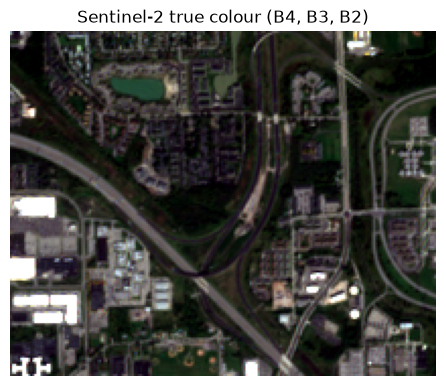

In [ ]:
img = ic.load_stack(DATA / "Images", sensor="Sentinel-2")          # (band, y, x) with CRS, transform and band names kept
print(dict(img.sizes), "| bands:", [str(b) for b in img.band.values])
print("pixel size (m):", img.rio.resolution())

pts = ic.labels_from_table(DATA / "Label_Point_Data" / "point_data.csv", label="Class_ID", crs=img.rio.crs)
X, y, coords = ic.sample_pixels(img, pts, "Class_ID")              # spectral vector at every labeled point
print(f"{len(X):,} labeled samples")
display(pd.Series(y).map(CLASSES).value_counts().rename("samples").to_frame())

def stretch(a, lo=2, hi=98):
    a = np.asarray(a, float)
    p0, p1 = np.nanpercentile(a, [lo, hi])
    return np.clip((a - p0) / (p1 - p0), 0, 1)

rgb = np.dstack([stretch(img.sel(band=b).values) for b in ("B4", "B3", "B2")])
plt.figure(figsize=(5.5, 4.6)); plt.imshow(rgb); plt.axis("off"); plt.title("Sentinel-2 true colour (B4, B3, B2)"); plt.show()

### Unsupervised: k-means clusters

No labels are used. The five clusters are numbered arbitrarily, so the colours below do not match the class colours. Comparing them with the true-colour image is how an analyst would name them.


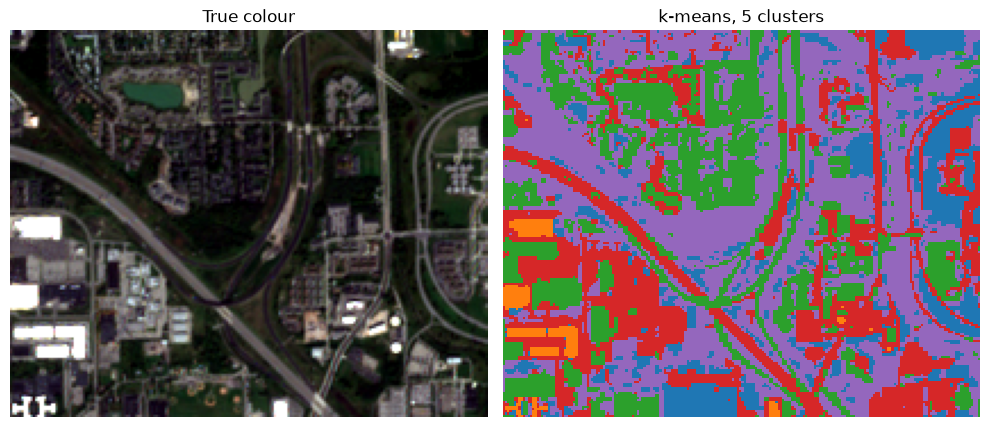

In [ ]:
clusters, km = ic.unsupervised_classify(img, n_classes=5, method="kmeans")
fig, ax = plt.subplots(1, 2, figsize=(10, 4.4))
ax[0].imshow(rgb); ax[0].set_title("True colour")
ax[1].imshow(clusters.values, cmap="tab10", vmin=0, vmax=9, interpolation="nearest"); ax[1].set_title("k-means, 5 clusters")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### Why the split matters: random versus spatial

The same random forest, scored two ways. A random split lets near-identical neighbouring pixels sit on both sides, so its score is optimistic. The spatial-block split holds out whole 200 m blocks and is the honest estimate of how the map behaves on ground the model has not seen.


In [ ]:
rf = lambda: Classifier("rf", n_estimators=150, random_state=0)

# Random pixel split (leaky)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
acc_random = (rf().fit(Xtr, ytr).predict(Xte) == yte).mean()

# Spatial block split (leakage-safe)
split = ic.spatial_block_split(coords, block_size=200, test_size=0.3, seed=0)
clf_s = rf().fit(X.iloc[split.train], y[split.train])
acc_spatial = (clf_s.predict(X.iloc[split.test]) == y[split.test]).mean()

print(f"random split accuracy : {acc_random:.3f}")
print(f"spatial split accuracy: {acc_spatial:.3f}")
print("train/test isolated   :", ic.check_split_isolation(train=coords[split.train].tolist() and range(len(split.train)),
                                                          test=range(len(split.train), len(split.train) + len(split.test))))

random split accuracy : 0.999
spatial split accuracy: 0.814
train/test isolated   : True


### Supervised, pixel-based: random forest with spatial cross-validation

`train_pixel_classifier` fits the model and, when coordinates and a block size are given, cross-validates by blocks. The spread across folds shows how much the score depends on *where* the test area is.


In [ ]:
clf, cv = ic.train_pixel_classifier(X.iloc[split.train], y[split.train], model="rf",
                                    coords=coords[split.train], block_size=200, n_estimators=150)
display(cv.round(3))

pred_test = clf.predict(X.iloc[split.test])
rep = ic.classification_report(y[split.test], pred_test, class_names=CLASSES, n_boot=200)
print(f"overall accuracy {rep['overall_accuracy']:.3f} | kappa {rep['kappa']:.3f} | macro-F1 {rep['macro_f1']:.3f}")
display(pd.DataFrame(rep["per_class"]).T.round(3) if isinstance(rep["per_class"], dict) else pd.DataFrame(rep["per_class"]).round(3))

pixel_map = ic.predict_map(clf, img)

,fold,n_train,n_test,accuracy,macro_f1,kappa
0,0,13042,5283,0.942,0.785,0.915
1,1,13468,4857,0.921,0.939,0.887
2,2,15554,2771,0.855,0.769,0.808
3,3,15567,2758,0.782,0.686,0.700
4,4,15669,2656,0.765,0.615,0.682


overall accuracy 0.814 | kappa 0.746 | macro-F1 0.838


,precision,recall,f1,support,f1_ci_low,f1_ci_high
Pavement/road,0.790,0.826,0.807,1307,0.790,0.824
Building,0.742,0.892,0.810,1602,0.797,0.826
Tree/bushes,0.844,0.665,0.744,1913,0.729,0.759
Grass,0.985,0.992,0.989,798,0.984,0.994
Water,0.000,NaN,NaN,0,NaN,NaN


### Supervised, object-based: SLIC segments

The image is first cut into about 800 segments. Each segment gets the mean and standard deviation of its bands, the labeled points give segment labels, a classifier is trained on segments and the labels are painted back on all pixels of each segment. The map is smoother and has no isolated pixels.


In [ ]:
obia = ic.object_based_classify(img, pts, "Class_ID", model="rf", n_segments=800, n_estimators=150)
object_map = obia["map"]
print("segments:", int(np.unique(obia["segments"].values).size), "| features per segment:", obia["features"].shape[1])

# Score both maps on the same held-out blocks: look up the map value at each test point.
def sample_map(m, xy):
    return np.array([m.sel(x=px, y=py, method="nearest").item() for px, py in xy])

xy_test = coords[split.test]
for name, m in [("pixel RF", pixel_map), ("object RF", object_map)]:
    p = sample_map(m, xy_test)
    print(f"{name:10s} accuracy on held-out blocks: {(p == y[split.test]).mean():.3f}")

segments: 716 | features per segment: 23


pixel RF   accuracy on held-out blocks: 0.814


object RF  accuracy on held-out blocks: 0.999


### Semi-supervised: self-training from 60 labels

Keep only 60 labeled samples from the training blocks and treat the rest as an unlabeled pool. Self-training fits a model, pseudo-labels the pool pixels it is at least 90 % sure about, and refits. The test blocks are never touched. Whether it helps depends on the data: compare the two numbers, and do not assume an improvement.


In [ ]:
rng = np.random.default_rng(0)
lab = rng.choice(split.train, 60, replace=False)
unl = np.setdiff1d(split.train, lab)

base = rf().fit(X.iloc[lab], y[lab])
st = ic.self_training(rf, X.iloc[lab], y[lab], X.iloc[unl], threshold=0.9, rounds=3,
                      X_val=X.iloc[split.test], y_val=y[split.test])
acc_base = (base.predict(X.iloc[split.test]) == y[split.test]).mean()
acc_st = (st["model"].predict(X.iloc[split.test]) == y[split.test]).mean()
print(f"60 labels, supervised only : {acc_base:.3f}")
print(f"60 labels + self-training  : {acc_st:.3f}   (pseudo-labeled pixels: {len(st['pseudo_labeled']):,})")

60 labels, supervised only : 0.702
60 labels + self-training  : 0.696   (pseudo-labeled pixels: 15,285)


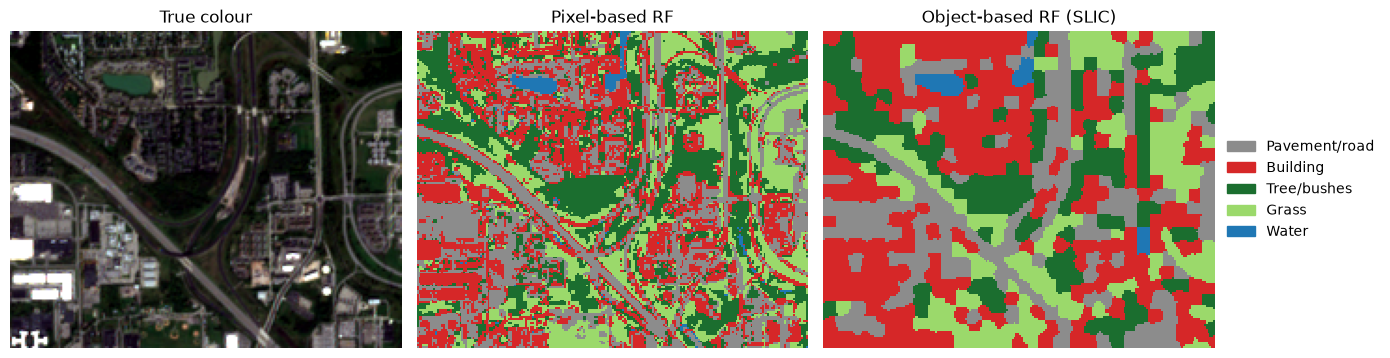

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
ax[0].imshow(rgb); ax[0].set_title("True colour")
for a, m, t in [(ax[1], pixel_map, "Pixel-based RF"), (ax[2], object_map, "Object-based RF (SLIC)")]:
    a.imshow(m.values, cmap=CMAP, vmin=1, vmax=5, interpolation="nearest"); a.set_title(t)
for a in ax: a.axis("off")
ax[2].legend(handles=HANDLES, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
plt.tight_layout(); plt.show()

### Deep learning, in outline

Deep models are built with one call and accept any number of bands. The table sizes a few of them for the ten Sentinel-2 bands. Training them properly (chips, augmentation, losses, transfer learning) is the subject of the next chapters, so here they are only built and run on a random tile to show the input and output shapes.


In [ ]:
import torch

rows = []
for kind, name, build in [
    ("scene classifier", "simple_cnn", lambda: ic.build_cnn("simple_cnn", in_channels=10, num_classes=5)),
    ("scene classifier", "resnet18",   lambda: ic.build_cnn("resnet18", in_channels=10, num_classes=5)),
    ("scene classifier", "efficientnet_b0", lambda: ic.build_cnn("efficientnet_b0", in_channels=10, num_classes=5)),
    ("scene classifier", "convnext_tiny", lambda: ic.build_cnn("convnext_tiny", in_channels=10, num_classes=5)),
    ("segmentation", "unet_basic", lambda: ic.build_segmenter("unet_basic", in_channels=10, num_classes=5)),
    ("segmentation", "unet (resnet34)", lambda: ic.build_segmenter("unet", in_channels=10, num_classes=5)),
]:
    try:
        m = build().eval()
        with torch.no_grad():
            out = m(torch.randn(1, 10, 64, 64))
        rows.append({"task": kind, "model": name, "parameters (M)": round(ic.count_parameters(m) / 1e6, 1),
                     "output for a 10 x 64 x 64 tile": tuple(out.shape)})
    except Exception as e:
        rows.append({"task": kind, "model": name, "parameters (M)": None, "output for a 10 x 64 x 64 tile": type(e).__name__})
display(pd.DataFrame(rows))

,task,model,parameters (M),output for a 10 x 64 x 64 tile
0,scene classifier,simple_cnn,0.0,"(1, 5)"
1,scene classifier,resnet18,11.2,"(1, 5)"
2,scene classifier,efficientnet_b0,4.0,"(1, 5)"
3,scene classifier,convnext_tiny,27.8,"(1, 5)"
4,segmentation,unet_basic,7.8,"(1, 5, 64, 64)"
5,segmentation,unet (resnet34),7.8,"(1, 5, 64, 64)"


A scene classifier returns one score vector per tile. A segmenter returns one score vector per pixel, which is the class map after an arg-max. Foundation models are listed with provenance and input requirements, so check the "preprocessing" and "license" columns before using one:


In [ ]:
display(ic.foundation_model_info()[["provider", "architecture", "inputs", "temporal", "loader"]])

,provider,architecture,inputs,temporal,loader
prithvi-eo-2.0,NASA / IBM,ViT MAE (3-D patch embedding),"HLS: blue, green, red, nir08, swir16, swir22",True,terratorch (BACKBONE_REGISTRY 'prithvi_eo_v2_3...
clay-v1.5,Clay Foundation,"ViT MAE, wavelength-aware patch embed",any sensor (band wavelengths supplied),via date metadata,claymodel / terratorch
satlaspretrain,Allen Institute for AI,Swin-v2 + FPN,"Sentinel-2 RGB or 9-band, NAIP, Landsat, Senti...",multi-image,torchgeo Swin_V2_B_Weights / satlaspretrain
dofa,TUM / Zhu lab,ViT with dynamic wavelength-conditioned stem,any band set (wavelengths in µm),False,torchgeo dofa_base_patch16_224
skysense,Ant Group / Wuhan University,multimodal factorized spatiotemporal encoder,"high-res optical, Sentinel-2 time series, Sent...",True,authors' code
ssl4eo-s12,TUM,"ResNet / ViT (MoCo, DINO, MAE, data2vec)","Sentinel-2 13 bands, Sentinel-1 VV/VH",seasonal views,torchgeo / load_rs_backbone
satmae,Stanford,ViT MAE with temporal/spectral encoding,fMoW RGB / Sentinel-2 10 bands,True,geolattice.rsense.dl.foundation.SatMAE
scale-mae,UC Berkeley,ViT MAE with GSD-aware positional encoding,RGB,False,timm-compatible ViT state dict


## Choosing a method

| Your situation | Start with | Then consider |
|---|---|---|
| No labels, first look at an area | `unsupervised_classify` | label a few clusters, move to supervised |
| Few hundred labeled points, medium resolution | `train_pixel_classifier` (random forest) with spatial CV | XGBoost; add indices, texture, dates |
| Very high resolution, parcels or buildings wanted as polygons | `object_based_classify` | a segmentation network, then `polygonize` |
| Many labeled masks, wall-to-wall map | `build_segmenter` + `sliding_window_predict` | pretrained encoder, boundary loss |
| Need counts or locations of objects | `build_object_detector` + `detect_objects` (chapter 09_10) | oriented boxes, `merge_detections` |
| Field boundaries or field polygons | `geolattice.rsense.edge_detectors` (09_10_02 to 09_10_04) | pretrained Fields of The World or Delineate Anything models |
| Crop type from a time series | `build_temporal_model` (TempCNN, L-TAE) | optical + SAR fusion |
| Two dates, find what changed | `change_vector_analysis`, `pca_change` | `build_change_model` |
| Few labels, lots of unlabeled imagery | `self_training`, `linear_probe` on `extract_embeddings` | `pretrain_contrastive`, a foundation model |
| Labels from an older or coarser map | `weak_labels_from_product` | noise-robust loss (`gce`, `sce`) |
| Model trained elsewhere | `histogram_match`, `coral` | `tent_adapt`, fine-tune with `set_trainable` |

Whatever the choice: split by geography, fit scalers on training data only, compare with a random-forest baseline, and report per-class results.


## The notebooks in this chapter

The 15 notebooks fall naturally into five groups, ordered from foundations to advanced topics. The numbering already mostly follows this order.

**1. Foundations**

| Notebook | Role |
|---|---|
| 09_09_01_01 Introduction | Tasks, learning modes, how to choose a method |
| 09_09_01_02 Image processing | Preparing images before classification |
| 09_09_01_03 Sampling, accuracy and reproducible runs | Spatial splits, accuracy, area estimates, `save_run` |

**2. Classical and CNN scene classification**

| Notebook | Role |
|---|---|
| 09_09_02_01 Pixel- and object-based classification | Random forest, SVM, XGBoost, SLIC and OBIA |
| 09_09_02_02 CNN on the GPU | First deep model; global vs tiled split |
| 09_09_02_03 Advanced CNNs | ResNet, EfficientNet, ConvNeXt, ViT, Swin |
| 09_09_02_04 Transfer learning and vision transformers | ImageNet vs remote-sensing weights |

**3. Time series and change**

| Notebook | Role |
|---|---|
| 09_09_03_01 Sentinel-1 crop classification | SAR time series |
| 09_09_03_02 Spatio-temporal, multi-sensor crop mapping | Optical + SAR + Landsat, 2020–2025 |
| 09_09_03_03 Paddy rice in Bangladesh | Sentinel-1 applied case study |
| 08_09_03_04 Change detection | Classical, post-classification and deep methods |

**4. Dense prediction (segmentation)**

| Notebook | Role |
|---|---|
| 09_09_04_01 Semantic segmentation | FCN, U-Net, DeepLabV3(+), SegFormer |
| 09_09_04_02 Instance segmentation | Mask R-CNN for fields |

**5. Learning with few or imperfect labels**

| Notebook | Role |
|---|---|
| 09_09_05_03 Imperfect labels and domain shift | Active learning, semi-supervised, weak and noisy labels, adaptation |
| 09_09_05_04 Image Fusion | Multi-Sensor Data Fusion |

Self-supervised pretraining (SimCLR, MoCo, MAE, linear probes) and foundation models (Prithvi, DOFA, SAM, RemoteCLIP, AlphaEarth and others) continue in chapter 08_11, starting with `09_11_01_self_supervised_pretraining_for_sentinel_2_crop_mapping.ipynb` and `09_11_02_geospatial_foundation_models_embeddings_promptable_segmentation_and_zero_shot_classification.ipynb`.


## Summary, exercises and references

### Summary

- Image classification is a family of tasks. Name the task (scene, pixel, detection, instance, change, time series) before choosing a model.
- The spatial unit (pixel or object) and the learning paradigm (unsupervised, supervised, semi-supervised, self-supervised) are independent choices.
- Computer-vision models need adapting to many bands, overhead views, spatial correlation, huge georeferenced scenes and repeated dates. GeoLattice wraps each adaptation.
- A random-forest baseline with spatial cross-validation is the reference every deeper model must beat, and spatial leakage is the main reason reported accuracies are too high.
- `geolattice.rsense.classify.image_classification` covers the whole path in 14 sections, from `load_stack` to `save_run`.
- The notebooks 09_09_01_01 to 09_09_05_04 (Section 12) work through these tasks on real data, chapter 08_10 continues with object detection and field boundaries, and chapter 08_11 with self-supervised pretraining and foundation models.


### Exercises

1. Change `block_size` in Section 10.3 to 50, 200 and 500 m. How does the spatial-split accuracy change, and why?
2. Run `unsupervised_classify` with `n_classes` of 3, 5 and 8, and with `method="gmm"`. Which clusters match the five classes?
3. Change `n_segments` in Section 10.5 to 200 and 3000. Where does the object map over- or under-segment?
4. Repeat Section 10.6 with 20, 60 and 200 labels and three seeds. When does self-training help, and when does it hurt?
5. Add NDVI and NDWI as extra features before `train_pixel_classifier`. Which classes improve?
6. Use `ic.foundation_model_info("prithvi-eo-2.0")` and write down which bands and normalization it needs. Could you feed it this scene as it stands?


### References

- Blaschke, T. (2010). Object based image analysis for remote sensing. *ISPRS Journal of Photogrammetry and Remote Sensing*, 65(1), 2-16.
- Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5-32.
- Chen, T., Kornblith, S., Norouzi, M., Hinton, G. (2020). A simple framework for contrastive learning of visual representations (SimCLR). *ICML*.
- Dosovitskiy, A. et al. (2021). An image is worth 16x16 words: transformers for image recognition at scale. *ICLR*.
- He, K., Zhang, X., Ren, S., Sun, J. (2016). Deep residual learning for image recognition. *CVPR*.
- He, K. et al. (2022). Masked autoencoders are scalable vision learners. *CVPR*.
- Kirillov, A. et al. (2023). Segment anything. *ICCV*.
- Olofsson, P. et al. (2014). Good practices for estimating area and assessing accuracy of land change. *Remote Sensing of Environment*, 148, 42-57.
- Ploton, P. et al. (2020). Spatial validation reveals poor predictive performance of large-scale ecological mapping models. *Nature Communications*, 11, 4540.
- Ren, S., He, K., Girshick, R., Sun, J. (2015). Faster R-CNN: towards real-time object detection with region proposal networks. *NeurIPS*.
- Roberts, D. R. et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, 40, 913-929.
- Ronneberger, O., Fischer, P., Brox, T. (2015). U-Net: convolutional networks for biomedical image segmentation. *MICCAI*.
- Sohn, K. et al. (2020). FixMatch: simplifying semi-supervised learning with consistency and confidence. *NeurIPS*.
- Zhu, X. X. et al. (2017). Deep learning in remote sensing: a comprehensive review and list of resources. *IEEE Geoscience and Remote Sensing Magazine*, 5(4), 8-36.
